In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

BASE = Path("D:/adaptive_federated_gnn")
DAY20 = BASE / "outputs" / "day20"
OUT = BASE / "outputs" / "day23"

OUT.mkdir(parents=True, exist_ok=True)

print("Day 20 output folder exists:", DAY20.exists())
print("Day 23 output folder:", OUT)
print("\nFiles available in Day 20:")

for path in sorted(DAY20.glob("*")):
    print(path.name)


Day 20 output folder exists: True
Day 23 output folder: D:\adaptive_federated_gnn\outputs\day23

Files available in Day 20:
three_model_comparison.png
three_model_metrics.csv
three_model_predictions.csv


In [2]:

metrics_path = DAY20 / "three_model_metrics.csv"
predictions_path = DAY20 / "three_model_predictions.csv"

if metrics_path.exists():
    metrics = pd.read_csv(metrics_path)
    print("MODEL METRICS")
    display(metrics.head())
    print("Metrics columns:", metrics.columns.tolist())
else:
    print("Metrics file not found:", metrics_path)

if predictions_path.exists():
    predictions = pd.read_csv(predictions_path)
    print("\nPREDICTION DATA")
    display(predictions.head())
    print("Prediction columns:", predictions.columns.tolist())
    print("Number of prediction records:", len(predictions))
else:
    print("Predictions file not found:", predictions_path)


MODEL METRICS


,model,accuracy,precision,recall,f1_score,roc_auc,pr_auc
0,Standard FedAvg,0.413275,0.007968,0.000462,0.000873,0.876633,0.789229
1,Adaptive FedAvg,0.412786,0.007849,0.000462,0.000872,0.876200,0.788830
2,Private FedAvg,0.572790,0.565121,0.999475,0.722007,0.423266,0.469131


Metrics columns: ['model', 'accuracy', 'precision', 'recall', 'f1_score', 'roc_auc', 'pr_auc']

PREDICTION DATA


,edge_index,actual_label,standard_fedavg_prediction,standard_fedavg_attack_probability,adaptive_fedavg_prediction,adaptive_fedavg_attack_probability,private_fedavg_prediction,private_fedavg_attack_probability
0,2,0,0,0.459778,0,0.460461,1,0.994819
1,5,0,0,0.457212,0,0.457916,1,0.998642
2,14,0,0,0.466843,0,0.467314,1,0.998379
3,15,0,0,0.480987,0,0.482132,1,0.999892
4,16,0,0,0.431740,0,0.432447,1,0.986732


Prediction columns: ['edge_index', 'actual_label', 'standard_fedavg_prediction', 'standard_fedavg_attack_probability', 'adaptive_fedavg_prediction', 'adaptive_fedavg_attack_probability', 'private_fedavg_prediction', 'private_fedavg_attack_probability']
Number of prediction records: 85829


In [3]:

if predictions_path.exists():
    print("Dataset shape:", predictions.shape)
    print("\nMissing values per column:")
    display(predictions.isna().sum())

    print("\nUnique values per column:")
    for column in predictions.columns:
        print(f"{column}: {predictions[column].nunique()} unique values")


Dataset shape: (85829, 8)

Missing values per column:


edge_index                            0
actual_label                          0
standard_fedavg_prediction            0
standard_fedavg_attack_probability    0
adaptive_fedavg_prediction            0
adaptive_fedavg_attack_probability    0
private_fedavg_prediction             0
private_fedavg_attack_probability     0
dtype: int64


Unique values per column:
edge_index: 85829 unique values
actual_label: 2 unique values
standard_fedavg_prediction: 2 unique values
standard_fedavg_attack_probability: 37542 unique values
adaptive_fedavg_prediction: 2 unique values
adaptive_fedavg_attack_probability: 37542 unique values
private_fedavg_prediction: 2 unique values
private_fedavg_attack_probability: 24688 unique values


important finding from Day 20: the three models behave very differently. Standard FedAvg and Adaptive FedAvg have extremely low attack recall in the saved evaluation, while Private FedAvg predicts nearly everything as an attack. means we investigate model behavior rather than assume the private model is better based on accuracy alone.
# Model Explainability and Prediction Analysis
continue using our existing results without retraining or changing previous models. First, we’ll examine how well each model classifies benign traffic and attacks.

In [4]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

model_columns = {
    "Standard FedAvg": "standard_fedavg_prediction",
    "Adaptive FedAvg": "adaptive_fedavg_prediction",
    "Private FedAvg": "private_fedavg_prediction"
}

actual = predictions["actual_label"].astype(int)

summary = []

for model_name, pred_column in model_columns.items():
    predicted = predictions[pred_column].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    print("\n" + "=" * 55)
    print(model_name)
    print("=" * 55)

    print("\nConfusion matrix:")
    print("                 Predicted Benign  Predicted Attack")
    print(f"Actual Benign       {tn:10d}       {fp:10d}")
    print(f"Actual Attack       {fn:10d}       {tp:10d}")

    print("\nClassification report:")
    print(classification_report(
        actual,
        predicted,
        labels=[0, 1],
        target_names=["Benign", "Attack"],
        zero_division=0
    ))

    summary.append({
        "model": model_name,
        "true_benign": int(tn),
        "false_alarms": int(fp),
        "missed_attacks": int(fn),
        "detected_attacks": int(tp),
        "predicted_benign": int((predicted == 0).sum()),
        "predicted_attack": int((predicted == 1).sum())
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

summary_path = OUT / "prediction_error_analysis.csv"
summary_df.to_csv(summary_path, index=False)

print("Saved analysis to:", summary_path)



Standard FedAvg

Confusion matrix:
                 Predicted Benign  Predicted Attack
Actual Benign            35449             2739
Actual Attack            47619               22

Classification report:
              precision    recall  f1-score   support

      Benign       0.43      0.93      0.58     38188
      Attack       0.01      0.00      0.00     47641

    accuracy                           0.41     85829
   macro avg       0.22      0.46      0.29     85829
weighted avg       0.19      0.41      0.26     85829


Adaptive FedAvg

Confusion matrix:
                 Predicted Benign  Predicted Attack
Actual Benign            35407             2781
Actual Attack            47619               22

Classification report:
              precision    recall  f1-score   support

      Benign       0.43      0.93      0.58     38188
      Attack       0.01      0.00      0.00     47641

    accuracy                           0.41     85829
   macro avg       0.22      0.46      

,model,true_benign,false_alarms,missed_attacks,detected_attacks,predicted_benign,predicted_attack
0,Standard FedAvg,35449,2739,47619,22,83068,2761
1,Adaptive FedAvg,35407,2781,47619,22,83026,2803
2,Private FedAvg,1546,36642,25,47616,1571,84258


Saved analysis to: D:\adaptive_federated_gnn\outputs\day23\prediction_error_analysis.csv


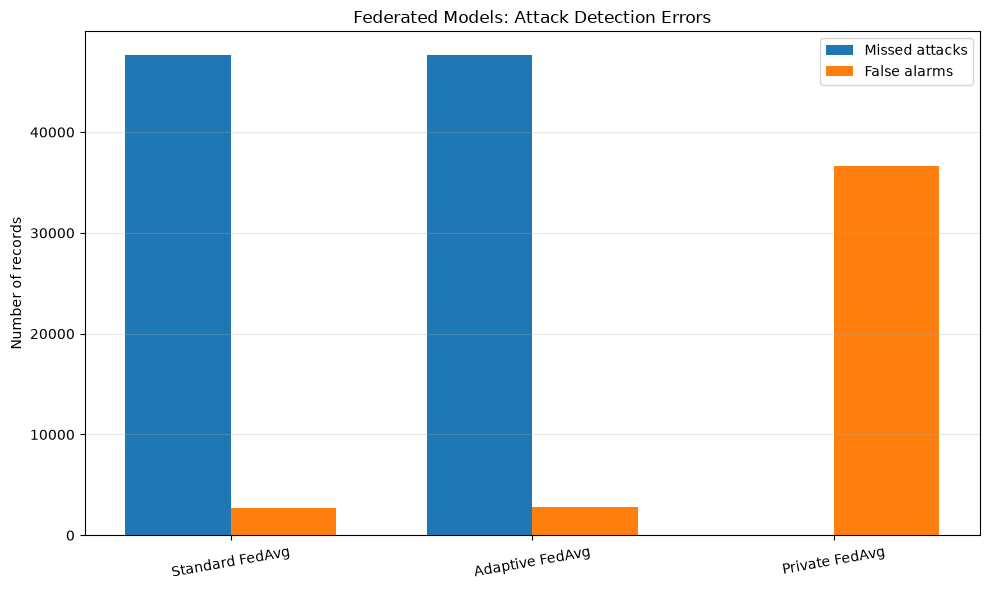

Chart saved to: D:\adaptive_federated_gnn\outputs\day23\model_error_comparison.png


In [5]:

import matplotlib.pyplot as plt
import numpy as np

plot_df = summary_df.set_index("model")

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(plot_df))
width = 0.35

ax.bar(
    x - width / 2,
    plot_df["missed_attacks"],
    width,
    label="Missed attacks"
)

ax.bar(
    x + width / 2,
    plot_df["false_alarms"],
    width,
    label="False alarms"
)

ax.set_title("Federated Models: Attack Detection Errors")
ax.set_ylabel("Number of records")
ax.set_xticks(x)
ax.set_xticklabels(plot_df.index, rotation=10)
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

chart_path = OUT / "model_error_comparison.png"
plt.savefig(chart_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path)


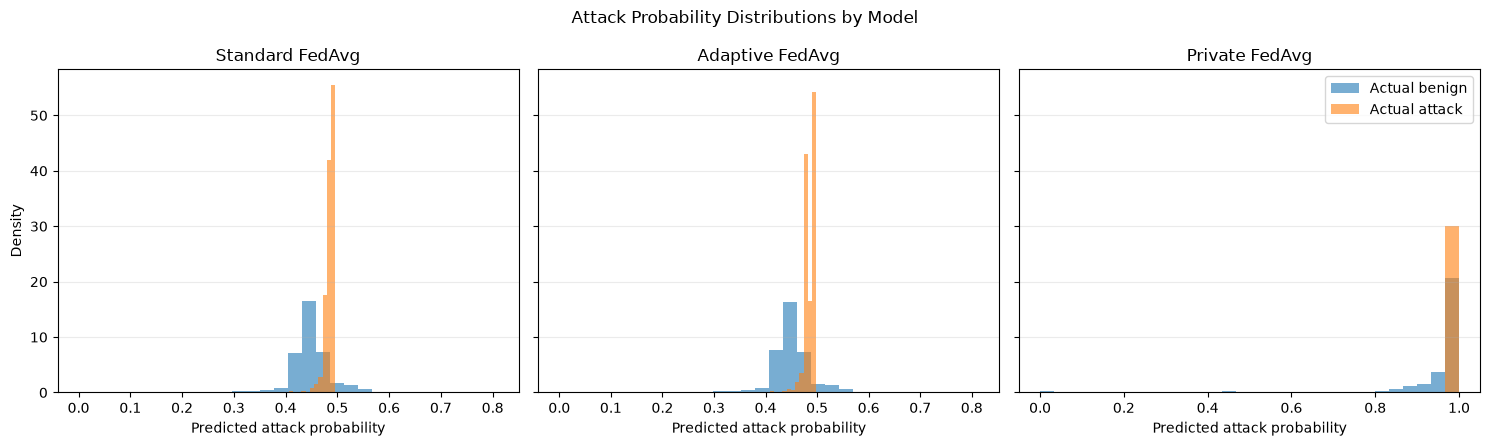

Chart saved to: D:\adaptive_federated_gnn\outputs\day23\attack_probability_distributions.png


In [6]:

probability_columns = {
    "Standard FedAvg": "standard_fedavg_attack_probability",
    "Adaptive FedAvg": "adaptive_fedavg_attack_probability",
    "Private FedAvg": "private_fedavg_attack_probability"
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)

for ax, (model_name, column) in zip(axes, probability_columns.items()):
    benign_probs = predictions.loc[
        actual == 0, column
    ].astype(float)

    attack_probs = predictions.loc[
        actual == 1, column
    ].astype(float)

    ax.hist(
        benign_probs,
        bins=30,
        alpha=0.6,
        label="Actual benign",
        density=True
    )

    ax.hist(
        attack_probs,
        bins=30,
        alpha=0.6,
        label="Actual attack",
        density=True
    )

    ax.set_title(model_name)
    ax.set_xlabel("Predicted attack probability")
    ax.grid(axis="y", alpha=0.25)

axes[0].set_ylabel("Density")
axes[-1].legend()
fig.suptitle("Attack Probability Distributions by Model")
plt.tight_layout()

probability_path = OUT / "attack_probability_distributions.png"
plt.savefig(probability_path, dpi=150, bbox_inches="tight")
plt.show()

print("Chart saved to:", probability_path)


In [7]:

operational_metrics = []

for model_name, pred_column in model_columns.items():
    predicted = predictions[pred_column].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        actual, predicted, labels=[0, 1]
    ).ravel()

    operational_metrics.append({
        "Model": model_name,
        "Attack Recall (%)": 100 * tp / (tp + fn) if tp + fn else 0,
        "False Positive Rate (%)": 100 * fp / (fp + tn) if fp + tn else 0,
        "Precision (%)": 100 * tp / (tp + fp) if tp + fp else 0,
        "Specificity (%)": 100 * tn / (tn + fp) if tn + fp else 0,
        "Accuracy (%)": 100 * (tp + tn) / (tp + tn + fp + fn)
    })

operational_df = pd.DataFrame(operational_metrics).round(2)
display(operational_df)

metrics_output = OUT / "operational_detection_metrics.csv"
operational_df.to_csv(metrics_output, index=False)

print("Saved to:", metrics_output)


,Model,Attack Recall (%),False Positive Rate (%),Precision (%),Specificity (%),Accuracy (%)
0,Standard FedAvg,0.05,7.17,0.80,92.83,41.33
1,Adaptive FedAvg,0.05,7.28,0.78,92.72,41.28
2,Private FedAvg,99.95,95.95,56.51,4.05,57.28


Saved to: D:\adaptive_federated_gnn\outputs\day23\operational_detection_metrics.csv
